# Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un **réseau de neurones convolutif** pour reconnaître les chiffres manuscrits de 0 à 9
(60 000 images d'entraînement, 10 000 de test, 28 × 28 pixels en niveaux de gris).

> Le premier lancement télécharge MNIST dans `data/` (déjà fait si l'exercice 2 a été exécuté).

## 1. Chargement des données

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


### Questions

**Que représentent les quatre dimensions du tenseur `images` ?**
`[64, 1, 28, 28]` = `[batch, canaux, hauteur, largeur]` : 64 images par lot, 1 canal (niveaux de gris ; ce serait 3 en RGB), 28 pixels de haut et 28 de large. C'est le format `N × C × H × W` attendu par `nn.Conv2d`.

**Pourquoi mélanger les données d'entraînement avec `shuffle=True` ?**
Pour que chaque mini-lot soit un échantillon **représentatif** et que l'ordre change à chaque époque. Sans mélange, les lots suivraient toujours le même ordre, par exemple de longues séries de la même classe si les données étaient triées. Les gradients seraient biaisés d'un lot à l'autre, l'apprentissage oscillerait et le modèle pourrait mémoriser l'ordre. Le test n'est pas mélangé : l'ordre ne change rien à l'évaluation.

## 2. Visualiser quelques images

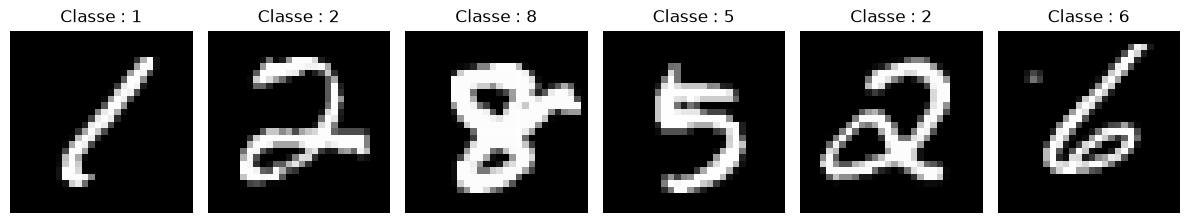

In [2]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Construire le CNN

| Couche | Paramètres | Sortie (hors batch) |
|---|---|---|
| Entrée | — | 1 × 28 × 28 |
| Convolution + ReLU | 16 filtres, noyau 3, padding 1 | 16 × 28 × 28 |
| Max pooling | noyau 2 | 16 × 14 × 14 |
| Convolution + ReLU | 32 filtres, noyau 3, padding 1 | 32 × 14 × 14 |
| Max pooling | noyau 2 | 32 × 7 × 7 |
| Flatten | — | 1568 |
| Linéaire + ReLU | 128 neurones | 128 |
| Linéaire | 10 classes | 10 |

In [3]:
class MNISTClassifier(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout),          # dropout=0.0 : sans effet (architecture de l'énoncé)
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

Sortie : torch.Size([64, 10])
Paramètres : 206922


In [4]:
# Suivre la forme du tenseur couche par couche
with torch.no_grad():
    x = images[:1].to(device)
    print(f"{'Entrée':<12} {tuple(x.shape)}")
    for couche in list(model.features) + list(model.classifier):
        x = couche(x)
        print(f"{couche.__class__.__name__:<12} {tuple(x.shape)}")

Entrée       (1, 1, 28, 28)
Conv2d       (1, 16, 28, 28)
ReLU         (1, 16, 28, 28)
MaxPool2d    (1, 16, 14, 14)
Conv2d       (1, 32, 14, 14)
ReLU         (1, 32, 14, 14)
MaxPool2d    (1, 32, 7, 7)
Flatten      (1, 1568)
Linear       (1, 128)
ReLU         (1, 128)
Dropout      (1, 128)
Linear       (1, 10)


**Pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?**
Le `padding=1` avec un noyau 3 conserve la taille spatiale. Chaque `MaxPool2d(2)` divise la hauteur et la largeur par 2 : 28 → 14 → 7. La dernière convolution produit **32 cartes** de caractéristiques, donc après deux poolings on a un tenseur 32 × 7 × 7. `Flatten` le transforme en un vecteur de 32 × 7 × 7 = **1568** valeurs par image.

## 4. Entraîner le réseau

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


def entrainer(model, optimizer, epochs=3):
    loss_history = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()                 # 1. Réinitialiser les gradients
            logits = model(images)                # 2. Calculer les scores
            loss = criterion(logits, labels)      # 3. Calculer la perte
            loss.backward()                       # 4. Calculer les gradients
            optimizer.step()                      # 5. Mettre à jour les paramètres

            total_loss += loss.item() * images.size(0)

        average_loss = total_loss / len(train_dataset)
        loss_history.append(average_loss)
        print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")
    return loss_history


loss_history = entrainer(model, optimizer, epochs=3)

Époque 1/3 | Perte : 0.1678


Époque 2/3 | Perte : 0.0481


Époque 3/3 | Perte : 0.0346


## 5. Évaluer sur le jeu de test

In [6]:
def evaluer(model):
    model.eval()
    correct, total = 0, 0
    toutes_predictions = []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            predictions = logits.argmax(dim=1)                  # classe au score le plus élevé
            correct += (predictions == labels).sum().item()     # bonnes prédictions
            total += labels.size(0)
            toutes_predictions.append(predictions.cpu())
    return correct / total, torch.cat(toutes_predictions)


accuracy, predictions = evaluer(model)
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.87%


## 6. Autres questions
### 10 images mal classées (vraie classe et prédiction)

Images mal classées : 113 sur 10000


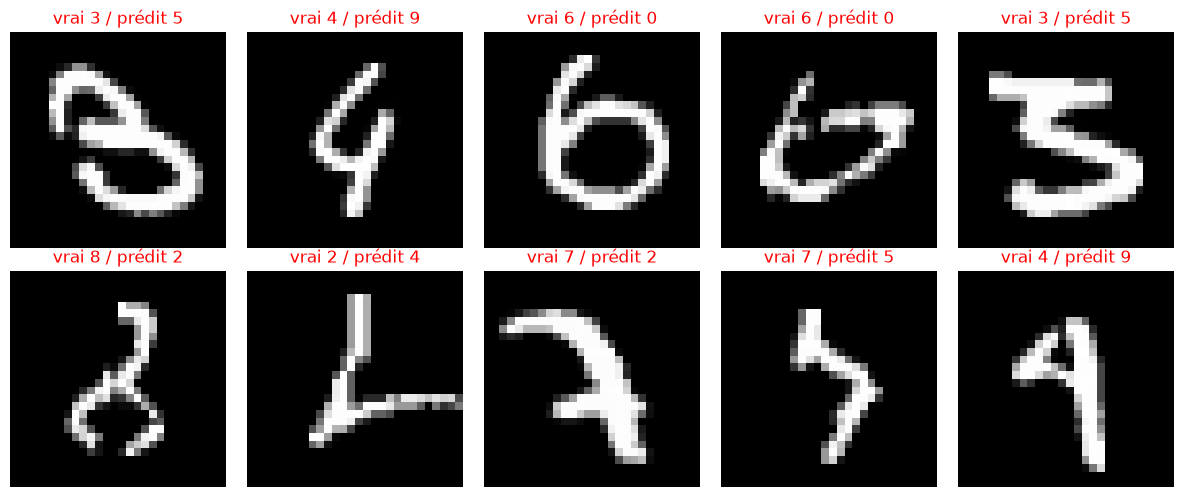

In [7]:
vraies = test_dataset.targets
mal_classees = (predictions != vraies).nonzero(as_tuple=True)[0]
print("Images mal classées :", len(mal_classees), "sur", len(vraies))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, mal_classees[:10]):
    image, vraie = test_dataset[idx.item()]
    ax.imshow(image[0] * 0.3081 + 0.1307, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"vrai {vraie} / prédit {predictions[idx].item()}", color="red")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Ajouter une couche Dropout avant la dernière couche linéaire

Le `Dropout(p=0.3)` éteint aléatoirement 30 % des 128 neurones pendant l'entraînement (`model.train()`),
ce qui limite le surapprentissage ; il est automatiquement désactivé en `model.eval()`.

In [8]:
torch.manual_seed(42)
model_dropout = MNISTClassifier(dropout=0.3).to(device)
print(model_dropout.classifier)

optimizer_dropout = torch.optim.Adam(model_dropout.parameters(), lr=0.001)
loss_history_dropout = entrainer(model_dropout, optimizer_dropout, epochs=3)
accuracy_dropout, _ = evaluer(model_dropout)

print(f"\nAccuracy test sans Dropout : {accuracy:.2%}")
print(f"Accuracy test avec Dropout : {accuracy_dropout:.2%}")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=1568, out_features=128, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=128, out_features=10, bias=True)
)


Époque 1/3 | Perte : 0.2051


Époque 2/3 | Perte : 0.0680


Époque 3/3 | Perte : 0.0511



Accuracy test sans Dropout : 98.87%
Accuracy test avec Dropout : 98.94%


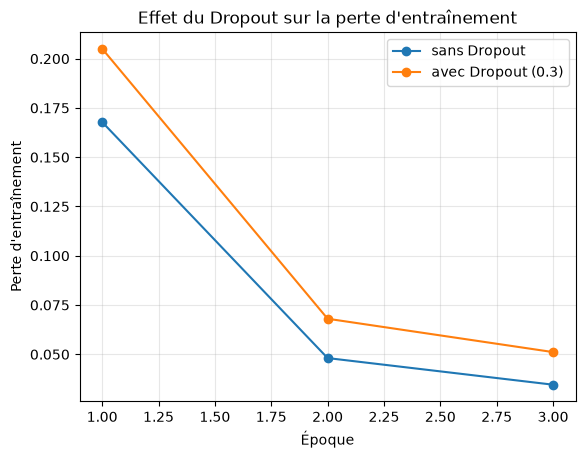

In [9]:
plt.plot(range(1, 4), loss_history, marker="o", label="sans Dropout")
plt.plot(range(1, 4), loss_history_dropout, marker="o", label="avec Dropout (0.3)")
plt.xlabel("Époque")
plt.ylabel("Perte d'entraînement")
plt.title("Effet du Dropout sur la perte d'entraînement")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

La perte d'entraînement est un peu plus élevée avec Dropout : le réseau est volontairement « gêné » pendant
l'apprentissage. L'accuracy de test reste du même ordre ; sur 3 époques le modèle ne surapprend presque pas encore,
le bénéfice du Dropout apparaît surtout avec plus d'époques.

### Sauvegarder les paramètres

In [10]:
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Paramètres sauvegardés dans mnist_cnn.pth")

# Vérification : recharger dans un nouveau modèle et retrouver la même accuracy
modele_recharge = MNISTClassifier().to(device)
modele_recharge.load_state_dict(torch.load("mnist_cnn.pth", weights_only=True))
accuracy_recharge, _ = evaluer(modele_recharge)
print(f"Accuracy du modèle rechargé : {accuracy_recharge:.2%}")

Paramètres sauvegardés dans mnist_cnn.pth


Accuracy du modèle rechargé : 98.87%


## Conclusion

- Les **convolutions** exploitent la structure 2D des images (filtres partagés sur toute l'image, invariance locale)
  avec beaucoup moins de poids par couche qu'une couche entièrement connectée.
- Le CNN dépasse 98 % d'accuracy en 3 époques, mieux que le réseau entièrement connecté de l'exercice 2 (≈ 97 %).
- Les erreurs restantes concernent surtout des chiffres mal écrits ou ambigus, souvent difficiles même pour un humain.